In [1]:
import gcinfo
import pandas as pd
import matplotlib.pyplot as plt

# 2021 Census ethnic or cultural origin. Private households, 25 percent sample.
# People can report more than one origin. The total is everyone who reported Ukrainian
# as at least one origin. Statistics Canada says this question is not comparable
# with earlier censuses, so earlier census counts are not plotted here.
gcinfo.search_titles(
    query='title:"Ethnic or cultural origin by gender and age: Canada, provinces and territories"',
    format_filter="CSV",
)


Ethnic or cultural origin by gender and age: Canada, provinces and territories and census subdivisions with a population 5,000 or more
Ethnic or cultural origin by gender and age: Canada, provinces and territories and census divisions
Ethnic or cultural origin by gender and age: Canada, provinces and territories, census metropolitan areas and census agglomerations with parts
Ethnic or cultural origin by gender and age: Canada, provinces and territories


In [2]:
datasets = gcinfo.search_datasets(
    query='title:"Ethnic or cultural origin by gender and age: Canada, provinces and territories"',
    rows=20,
)["results"]
dataset = next(
    item
    for item in datasets
    if item["title"]
    == "Ethnic or cultural origin by gender and age: Canada, provinces and territories"
)
gcinfo.list_resources(dataset)



=== Ethnic or cultural origin by gender and age: Canada, provinces and territories ===
ID: f1a937b2-ced6-4773-8a11-2282150ed2dd
Org: Statistics Canada | Statistique Canada
Notes: Data on ethnic or cultural origin by gender and age for the population in private households in Canada, provinces and territories....
URL: https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=9810035501
Citation: Statistics Canada. Table 98-10-0355-01 Ethnic or cultural origin by gender and age: Canada, provinces and territories
DOI:      https://doi.org/10.25318/9810035501-eng
  [CSV     ] Dataset
           https://www150.statcan.gc.ca/n1/tbl/csv/98100355-fra.zip
  [CSV     ] Dataset
           https://www150.statcan.gc.ca/n1/tbl/csv/98100355-eng.zip
  [XML     ] Dataset
           https://www150.statcan.gc.ca/n1/tbl/sdmx/98100355-SDMX.zip


In [3]:
df_origin, _ = gcinfo.download_zip(
    "https://www150.statcan.gc.ca/n1/tbl/csv/98100355-eng.zip",
    return_metadata=False,
)

origin_col = next(column for column in df_origin.columns if "(530)" in column)
total_col = next(column for column in df_origin.columns if column.endswith("[1]"))
single_col = next(column for column in df_origin.columns if column.endswith("[2]"))
multiple_col = next(column for column in df_origin.columns if column.endswith("[3]"))

origin = df_origin[
    (df_origin["GEO"] == "Canada")
    & (df_origin["Age (15C)"] == "Total - Age")
    & (df_origin["Gender (3)"] == "Total - Gender")
    & (df_origin["Statistics (3)"] == "Count")
    & (df_origin[origin_col] == "Ukrainian")
].iloc[0]

origin_counts = pd.DataFrame(
    {
        "Response": ["Total", "Single Response", "Multiple Responses"],
        "People": [
            int(origin[total_col]),
            int(origin[single_col]),
            int(origin[multiple_col]),
        ],
    }
)
origin_counts


Using cached file: cache\98100355-eng.zip


,Response,People
0,Total,1258635
1,Single Response,273210
2,Multiple Responses,985425


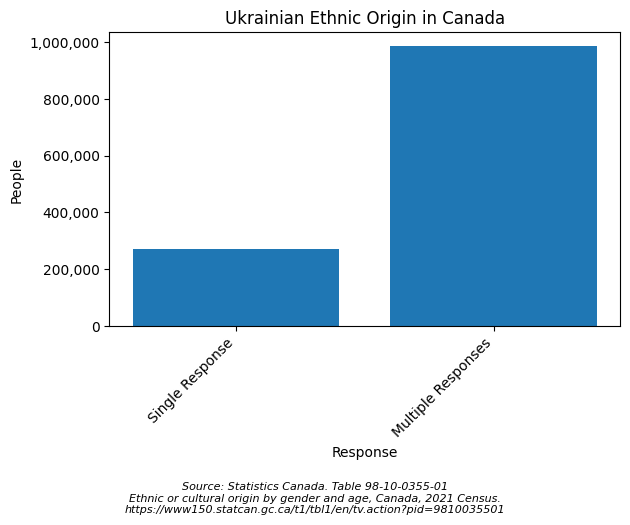

In [4]:
fig, ax = plt.subplots()
bars = origin_counts[origin_counts["Response"] != "Total"]
ax.bar(bars["Response"], bars["People"])
ax.set_title("Ukrainian Ethnic Origin in Canada")
ax.set_xlabel("Response")
ax.set_ylabel("People")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:,.0f}"))
plt.figtext(
    0.5,
    -0.08,
    "Source: Statistics Canada. Table 98-10-0355-01\n"
    "Ethnic or cultural origin by gender and age, Canada, 2021 Census.\n"
    "https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=9810035501",
    ha="center",
    fontsize=8,
    style="italic",
)
plt.subplots_adjust(bottom=0.36)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [5]:
# Place of birth on Census day, May 11, 2021, before the 2022 invasion.
# The total is everyone born in Ukraine. Non permanent residents are one part of that total.
gcinfo.search_titles(
    query='title:"Non-permanent resident type by place of birth: Canada, provinces and territories, census metropolitan areas and census agglomerations with parts"',
    format_filter="CSV",
)


429 sleep 20


429 sleep 40


Non-permanent resident type by place of birth: Canada, provinces and territories, census metropolitan areas and census agglomerations with parts


In [6]:
datasets = gcinfo.search_datasets(
    query='title:"Non-permanent resident type by place of birth: Canada, provinces and territories, census metropolitan areas and census agglomerations with parts"',
    rows=10,
)["results"]
dataset = next(
    item
    for item in datasets
    if item["title"]
    == "Non-permanent resident type by place of birth: Canada, provinces and territories, census metropolitan areas and census agglomerations with parts"
)
gcinfo.list_resources(dataset)



=== Non-permanent resident type by place of birth: Canada, provinces and territories, census metropolitan areas and census agglomerations with parts ===
ID: 64d9dd72-2c5b-4eac-9c82-f3160f15d267
Org: Statistics Canada | Statistique Canada
Notes: Data on non-permanent resident type by place of birth, age and gender for the population in private households in Canada, provinces and territories, census metropolitan areas, census agglomerations an...
URL: https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=9810036101
Citation: Statistics Canada. Table 98-10-0361-01 Non-permanent resident type by place of birth: Canada, provinces and territories, census metropolitan areas and census agglomerations with parts
DOI:      https://doi.org/10.25318/9810036101-eng
  [CSV     ] Dataset
           https://www150.statcan.gc.ca/n1/tbl/csv/98100361-fra.zip
  [CSV     ] Dataset
           https://www150.statcan.gc.ca/n1/tbl/csv/98100361-eng.zip
  [XML     ] Dataset
           https://www150.statcan.gc.

In [7]:
import csv
import io
import zipfile

# The full table is about a gigabyte. Read only the Canada total row for Ukraine.
birth_url = "https://www150.statcan.gc.ca/n1/tbl/csv/98100361-eng.zip"
birth_path = gcinfo.CACHE_DIR / "98100361-eng.zip"
if not birth_path.exists():
    gcinfo.download_zip(birth_url)

birth_row = None
with zipfile.ZipFile(birth_path) as archive:
    with archive.open("98100361.csv") as raw:
        reader = csv.reader(io.TextIOWrapper(raw, encoding="utf-8-sig", newline=""))
        header = next(reader)
        for row in reader:
            if (
                row[1] == "Canada"
                and row[3] == "Total - Gender"
                and row[4] == "Total - Age"
                and row[5] == "Count"
                and row[6] == "Ukraine"
            ):
                birth_row = row
                break

if birth_row is None:
    raise ValueError("Ukraine place of birth row was not found")

def birth_value(label):
    index = next(i for i, name in enumerate(header) if label in name)
    return int(birth_row[index])

birth_counts = pd.DataFrame(
    {
        "Group": ["Immigrants", "Non Immigrants", "Non Permanent Residents"],
        "People": [
            birth_value("Immigrants[10]"),
            birth_value("Non-immigrants[9]"),
            birth_value("Non-permanent residents[2]"),
        ],
    }
)
birth_total = birth_value("Total - Non-permanent resident type[1]")
print(birth_total)
birth_counts


87505


,Group,People
0,Immigrants,81135
1,Non Immigrants,980
2,Non Permanent Residents,5390


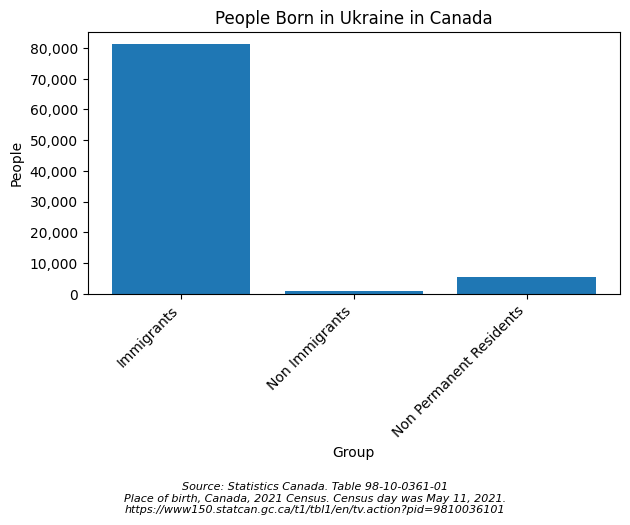

In [8]:
fig, ax = plt.subplots()
ax.bar(birth_counts["Group"], birth_counts["People"])
ax.set_title("People Born in Ukraine in Canada")
ax.set_xlabel("Group")
ax.set_ylabel("People")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:,.0f}"))
plt.figtext(
    0.5,
    -0.08,
    "Source: Statistics Canada. Table 98-10-0361-01\n"
    "Place of birth, Canada, 2021 Census. Census day was May 11, 2021.\n"
    "https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=9810036101",
    ha="center",
    fontsize=8,
    style="italic",
)
plt.subplots_adjust(bottom=0.36)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [9]:
# Permanent resident admissions by country of citizenship. This is a flow, not a population stock.
gcinfo.search_titles(
    query='title:"Permanent Residents – Monthly IRCC Updates"',
    rows=50,
)


429 sleep 20


Express Entry Permanent Residents – Monthly IRCC Updates
Permanent Residents – Monthly IRCC Updates


In [10]:
datasets = gcinfo.search_datasets(
    query='title:"Permanent Residents – Monthly IRCC Updates"',
    rows=50,
)["results"]
dataset = next(
    item for item in datasets if item["title"] == "Permanent Residents – Monthly IRCC Updates"
)
gcinfo.list_resources(dataset)



=== Permanent Residents – Monthly IRCC Updates ===
ID: f7e5498e-0ad8-4417-85c9-9b8aff9b9eda
Org: Immigration, Refugees and Citizenship Canada | Immigration, Réfugiés et Citoyenneté Canada
Notes: People who have been granted permanent resident status in Canada.

Please note that in these datasets, the figures have been suppressed or rounded to prevent the identification of individuals when t...
Citation: Immigration, Refugees and Citizenship Canada. Permanent Residents – Monthly IRCC Updates
  [XLSX    ] Canada - Permanent Residents by Province/Territory and Immigration Category
           https://www.ircc.canada.ca/opendata-donneesouvertes/data/EN_ODP-PR-ProvImmCat.xlsx
  [XLSX    ] Canada - Permanent Residents by Province/Territory and Immigration Category
           https://www.ircc.canada.ca/opendata-donneesouvertes/data/FR_ODP-PR-ProvImmCat.xlsx
  [CSV     ] [rounded - not for calculations] Canada - Permanent resident by province/territory and immigration category
           https

In [11]:
df = gcinfo.download_xlsx(
    "https://www.ircc.canada.ca/opendata-donneesouvertes/data/EN_ODP-PR-Citz.xlsx"
)

year_row = df.iloc[1]
quarter_row = df.iloc[2]
month_row = df.iloc[3]
ukraine = df.loc[df.iloc[:, 0] == "Ukraine"].iloc[0]

full_months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

records = []
for i, label in enumerate(quarter_row.tolist()):
    if not (isinstance(label, str) and label[:4].isdigit() and label.endswith(" Total")):
        continue
    year = int(label[:4])
    starts = [j for j, value in enumerate(year_row.tolist()) if str(value) == str(year)]
    start = starts[0]
    months_present = [
        str(value) for value in month_row.iloc[start : i + 1].tolist() if pd.notna(value)
    ]
    # A year still missing a month is left out.
    if not all(month in months_present for month in full_months):
        continue
    admissions = int(str(ukraine.iloc[i]).replace(",", "").replace("--", "0"))
    records.append({"Year": year, "Admissions": admissions})

admissions = pd.DataFrame(records)
admissions


Using cached file: cache\EN_ODP-PR-Citz.xlsx


,Year,Admissions
0,2015,2345
1,2016,3350
2,2017,3310
3,2018,3135
4,2019,2995
5,2020,1675
6,2021,3190
7,2022,3575
8,2023,3110
9,2024,6780


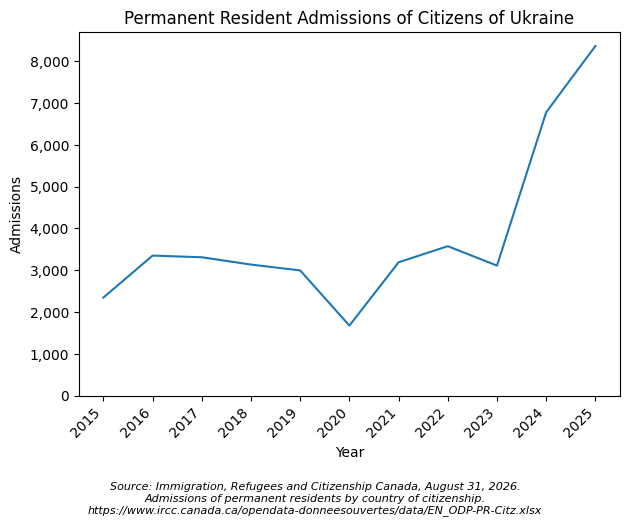

In [12]:
fig, ax = plt.subplots()
ax.plot(admissions["Year"], admissions["Admissions"], linestyle="-")
ax.set_title("Permanent Resident Admissions of Citizens of Ukraine")
ax.set_xlabel("Year")
ax.set_ylabel("Admissions")
ax.set_ylim(bottom=0)
ax.set_xticks(admissions["Year"].tolist())
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:,.0f}"))
plt.figtext(
    0.5,
    -0.08,
    "Source: Immigration, Refugees and Citizenship Canada, August 31, 2026.\n"
    "Admissions of permanent residents by country of citizenship.\n"
    "https://www.ircc.canada.ca/opendata-donneesouvertes/data/EN_ODP-PR-Citz.xlsx",
    ha="center",
    fontsize=8,
    style="italic",
)
plt.subplots_adjust(bottom=0.36)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [13]:
# Press and committee pages are snapshots. They are not one downloadable series.
# Key figures stopped updating on July 26, 2024 and the page says the data are approximate.
# The February 28, 2026 committee table is operational. Its approved count is lower
# than the frozen key figures page, and the pages do not explain the difference.
# Arrivals count people who came under CUAET, including family members of any nationality.
# They are not a count of people still in Canada.
# Rounded lines that are not plotted: July 15, 2023 news release, over 166000;
# October 23, 2023 notice, over 185000; April 4, 2024 notice, more than 286700
# as of March 23, 2024; May 28, 2026 committee note, over 300000 welcomed and
# over 3200 family pathway approvals.
#
# https://www.canada.ca/en/immigration-refugees-citizenship/corporate/transparency/committees/cimm-dec-05-2023/canada-ukraine-overview.html
# https://www.canada.ca/en/immigration-refugees-citizenship/services/immigrate-canada/ukraine-measures/key-figures.html
# https://www.canada.ca/en/immigration-refugees-citizenship/corporate/transparency/committees/secu-apr-30-2026/data-tables-responses-recent-crises.html
# https://www.canada.ca/en/immigration-refugees-citizenship/corporate/transparency/committees/cow-may-28-2026/ukraine.html

press = pd.DataFrame(
    [
        ["14 Nov 2023", "Applications Received", 1189292, "CIMM overview"],
        ["14 Nov 2023", "Applications Approved", 931659, "CIMM overview"],
        ["14 Nov 2023", "Arrivals", 205917, "CIMM overview"],
        ["1 Apr 2024", "Applications Received", 1189320, "Key figures, approximate"],
        ["1 Apr 2024", "Applications Approved", 962612, "Key figures, approximate"],
        ["1 Apr 2024", "Arrivals", 298128, "Key figures, approximate"],
        ["28 Feb 2026", "Applications Received", 1189320, "SECU table, intake closed 15 Jul 2023"],
        ["28 Feb 2026", "Applications Approved", 815315, "SECU table, operational"],
        ["28 Feb 2026", "Arrivals", 308450, "SECU table, operational"],
        ["28 Feb 2026", "Family Pathway Applications", 25235, "SECU table, persons, pathway closed 22 Oct 2024"],
        ["28 Feb 2026", "Family Pathway Approved", 3295, "SECU table, persons"],
    ],
    columns=["Date", "Measure", "Count", "Note"],
)
press


,Date,Measure,Count,Note
0,14 Nov 2023,Applications Received,1189292,CIMM overview
1,14 Nov 2023,Applications Approved,931659,CIMM overview
2,14 Nov 2023,Arrivals,205917,CIMM overview
3,1 Apr 2024,Applications Received,1189320,"Key figures, approximate"
4,1 Apr 2024,Applications Approved,962612,"Key figures, approximate"
5,1 Apr 2024,Arrivals,298128,"Key figures, approximate"
6,28 Feb 2026,Applications Received,1189320,"SECU table, intake closed 15 Jul 2023"
7,28 Feb 2026,Applications Approved,815315,"SECU table, operational"
8,28 Feb 2026,Arrivals,308450,"SECU table, operational"
9,28 Feb 2026,Family Pathway Applications,25235,"SECU table, persons, pathway closed 22 Oct 2024"


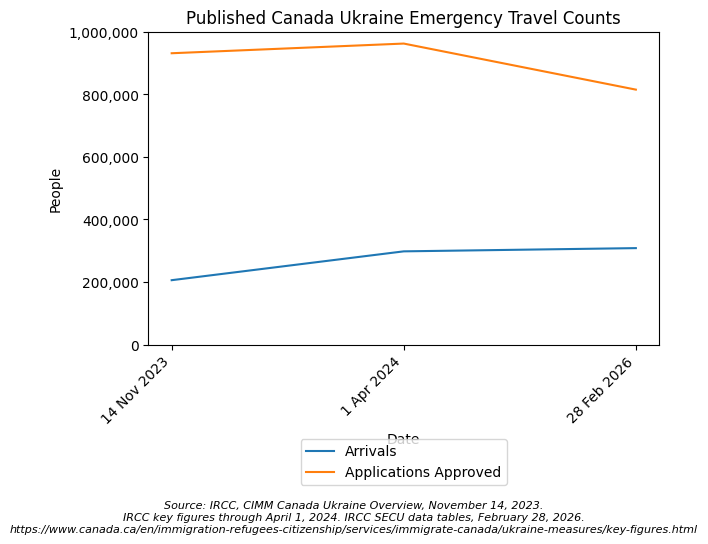

In [14]:
fig, ax = plt.subplots()
dates = ["14 Nov 2023", "1 Apr 2024", "28 Feb 2026"]
arrivals = press.loc[press["Measure"] == "Arrivals", "Count"].tolist()
approved = press.loc[press["Measure"] == "Applications Approved", "Count"].tolist()
ax.plot(dates, arrivals, linestyle="-", label="Arrivals")
ax.plot(dates, approved, linestyle="-", label="Applications Approved")
ax.set_title("Published Canada Ukraine Emergency Travel Counts")
ax.set_xlabel("Date")
ax.set_ylabel("People")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:,.0f}"))
ax.legend(
    title=None,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.28),
    ncol=1,
    frameon=True,
)
plt.figtext(
    0.5,
    -0.12,
    "Source: IRCC, CIMM Canada Ukraine Overview, November 14, 2023.\n"
    "IRCC key figures through April 1, 2024. IRCC SECU data tables, February 28, 2026.\n"
    "https://www.canada.ca/en/immigration-refugees-citizenship/services/immigrate-canada/ukraine-measures/key-figures.html",
    ha="center",
    fontsize=8,
    style="italic",
)
plt.subplots_adjust(bottom=0.42)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
